Epoch 100, Reconstruction Error: 0.2433
Epoch 200, Reconstruction Error: 0.2175
Epoch 300, Reconstruction Error: 0.1546
Epoch 400, Reconstruction Error: 0.1561
Epoch 500, Reconstruction Error: 0.1361

GENERATED SAMPLES
[[1. 1. 1. 0. 0. 0.]
 [1. 1. 0. 0. 1. 0.]]

LEARNED WEIGHTS
[[ 2.25496857  0.06799374 -3.00934771]
 [ 0.82558817  0.23545512 -0.60174456]
 [ 0.78179933  0.58394485 -0.45411586]
 [-2.37090111 -0.2476231   2.72250628]
 [ 0.5238714  -0.51293181 -0.85843016]
 [-2.36399131 -0.20233902  2.88494167]]


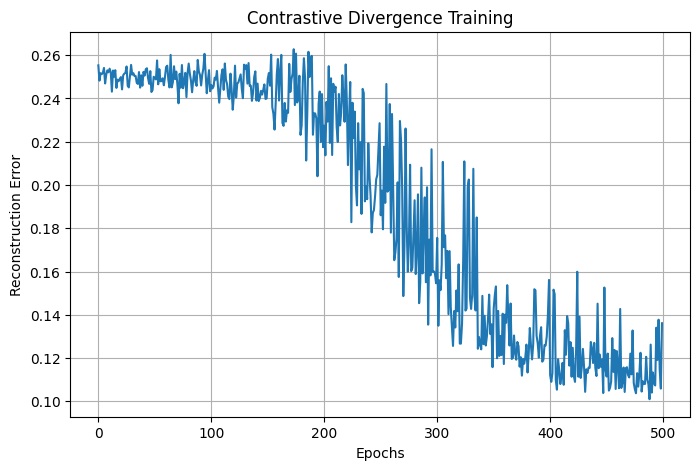

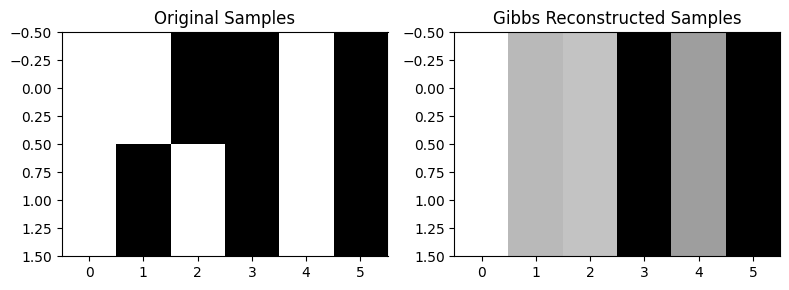

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import expit

np.random.seed(42)

# 1. Define RBM parameters
n_visible = 6
n_hidden = 3

W = np.random.normal(
    0, 0.1,
    (n_visible, n_hidden)
)

vb = np.zeros(n_visible)
hb = np.zeros(n_hidden)

learning_rate = 0.1

# 2. Training dataset
X = np.array([
    [1, 1, 0, 0, 1, 0],
    [1, 0, 1, 0, 1, 0],
    [0, 1, 0, 1, 0, 1],
    [0, 0, 1, 1, 0, 1],
    [1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 1, 1]
], dtype=float)

# 3. Hidden layer sampling
def sample_hidden(v):

    probability = expit(
        np.dot(v, W) + hb
    )

    sample = (
        np.random.random(probability.shape)
        < probability
    ).astype(float)

    return probability, sample

# 4. Visible layer sampling
def sample_visible(h):

    probability = expit(
        np.dot(h, W.T) + vb
    )

    sample = (
        np.random.random(probability.shape)
        < probability
    ).astype(float)

    return probability, sample

# 5. Gibbs Sampling
def gibbs_sampling(v, steps=5):

    for _ in range(steps):

        _, h = sample_hidden(v)

        v_prob, v = sample_visible(h)

    return v_prob, v

# 6. Contrastive Divergence training
epochs = 500

errors = []

for epoch in range(epochs):

    # Positive phase
    positive_hidden_prob, positive_hidden = sample_hidden(X)

    # Negative phase using Gibbs sampling
    negative_visible_prob, negative_visible = gibbs_sampling(
        X,
        steps=1
    )

    negative_hidden_prob, _ = sample_hidden(
        negative_visible
    )

    # Weight update
    W += learning_rate * (
        np.dot(X.T, positive_hidden_prob)
        - np.dot(negative_visible.T, negative_hidden_prob)
    ) / len(X)

    # Bias updates
    vb += learning_rate * np.mean(
        X - negative_visible_prob,
        axis=0
    )

    hb += learning_rate * np.mean(
        positive_hidden_prob - negative_hidden_prob,
        axis=0
    )

    # Reconstruction error
    error = np.mean(
        (X - negative_visible_prob) ** 2
    )

    errors.append(error)

    if (epoch + 1) % 100 == 0:

        print(
            f"Epoch {epoch+1}, "
            f"Reconstruction Error: {error:.4f}"
        )

# 7. Perform Gibbs sampling
sample = X[:2].copy()

generated_prob, generated_sample = gibbs_sampling(
    sample,
    steps=10
)

print("\nGENERATED SAMPLES")

print(generated_sample)

# 8. Display learned weights
print("\nLEARNED WEIGHTS")

print(W)

# 9. Plot reconstruction error
plt.figure(figsize=(8, 5))

plt.plot(errors)

plt.xlabel("Epochs")

plt.ylabel("Reconstruction Error")

plt.title("Contrastive Divergence Training")

plt.grid()

plt.show()

# 10. Visualize generated samples
plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)

plt.imshow(X[:2], cmap="gray", aspect="auto")

plt.title("Original Samples")

plt.subplot(1, 2, 2)

plt.imshow(
    generated_prob,
    cmap="gray",
    aspect="auto"
)

plt.title("Gibbs Reconstructed Samples")

plt.tight_layout()

plt.show()